# StudySync — Local Question-Generation Model

Fine-tune **T5-small** to turn a sentence (with a highlighted answer) into a natural question, then export it to **ONNX** so it can run **in the browser** via `@xenova/transformers` — no API, no rate limit.

**Pipeline:** SQuAD → fine-tune T5-small → test → export ONNX → use in `src/ml-ai/questionGen.js`.

**Run this on a GPU** (Google Colab free tier works: Runtime → Change runtime type → T4 GPU). A 20k-example, 2-epoch run takes ~30–45 min.

**Input format (answer-highlighting):**
`generate question: Concurrent programming is <hl> the practice of managing multiple computations at once <hl> .`
→ target question: `What is concurrent programming?`

## 1. Install dependencies

In [12]:
# NOTE: torch is installed separately with the CUDA build — don't let these pull the CPU wheel.
# If running on Colab, torch+CUDA is preinstalled, so this is fine there too.
!pip install -q "transformers==4.44.2" "datasets==2.21.0" "evaluate" "sentencepiece" "accelerate" "optimum[exporters]"


[notice] A new release of pip is available: 25.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
# Verify the GPU is actually visible — training silently falls back to (very slow) CPU otherwise.
import torch
assert torch.cuda.is_available(), (
    "No CUDA GPU visible. Install a CUDA build of torch, e.g. for RTX 50-series (Blackwell):\n"
    "  pip uninstall -y torch\n"
    "  pip install torch --index-url https://download.pytorch.org/whl/cu128"
)
print("Device:", torch.cuda.get_device_name(0))
print("Compute capability: sm_%d%d" % torch.cuda.get_device_capability(0))
print("VRAM: %.1f GB" % (torch.cuda.get_device_properties(0).total_memory / 1e9))

Device: NVIDIA GeForce RTX 5060
Compute capability: sm_120
VRAM: 8.5 GB


## 2. Load the SQuAD dataset
Each example has a context, a question, and the answer span (text + start index).

In [14]:
from datasets import load_dataset

raw = load_dataset("squad")
print(raw)
print(raw["train"][0])

DatasetDict({
    train: Dataset({
        features: ['id', 'title', 'context', 'question', 'answers'],
        num_rows: 87599
    })
    validation: Dataset({
        features: ['id', 'title', 'context', 'question', 'answers'],
        num_rows: 10570
    })
})
{'id': '5733be284776f41900661182', 'title': 'University_of_Notre_Dame', 'context': 'Architecturally, the school has a Catholic character. Atop the Main Building\'s gold dome is a golden statue of the Virgin Mary. Immediately in front of the Main Building and facing it, is a copper statue of Christ with arms upraised with the legend "Venite Ad Me Omnes". Next to the Main Building is the Basilica of the Sacred Heart. Immediately behind the basilica is the Grotto, a Marian place of prayer and reflection. It is a replica of the grotto at Lourdes, France where the Virgin Mary reputedly appeared to Saint Bernadette Soubirous in 1858. At the end of the main drive (and in a direct line that connects through 3 statues and the Gold Dome

## 3. Preprocess into question-generation format
We wrap the answer span in `<hl>` tokens inside the context, prefix `generate question:`, and use the original question as the target.

In [15]:
from transformers import AutoTokenizer

MODEL_CKPT = "t5-small"
MAX_IN, MAX_OUT = 384, 64
HL = "<hl>"

tokenizer = AutoTokenizer.from_pretrained(MODEL_CKPT)
tokenizer.add_tokens([HL])  # add the highlight marker as a real token

def make_example(ex):
    context = ex["context"]
    answer = ex["answers"]["text"][0]
    start = ex["answers"]["answer_start"][0]
    end = start + len(answer)
    hl_context = f"{context[:start]} {HL} {answer} {HL} {context[end:]}"
    return {"src": "generate question: " + hl_context, "tgt": ex["question"]}

proc = raw.map(make_example, remove_columns=raw["train"].column_names)
print(proc["train"][0])

{'src': 'generate question: Architecturally, the school has a Catholic character. Atop the Main Building\'s gold dome is a golden statue of the Virgin Mary. Immediately in front of the Main Building and facing it, is a copper statue of Christ with arms upraised with the legend "Venite Ad Me Omnes". Next to the Main Building is the Basilica of the Sacred Heart. Immediately behind the basilica is the Grotto, a Marian place of prayer and reflection. It is a replica of the grotto at Lourdes, France where the Virgin Mary reputedly appeared to  <hl> Saint Bernadette Soubirous <hl>  in 1858. At the end of the main drive (and in a direct line that connects through 3 statues and the Gold Dome), is a simple, modern stone statue of Mary.', 'tgt': 'To whom did the Virgin Mary allegedly appear in 1858 in Lourdes France?'}


In [16]:
def tokenize(batch):
    model_inputs = tokenizer(batch["src"], max_length=MAX_IN, truncation=True)
    labels = tokenizer(text_target=batch["tgt"], max_length=MAX_OUT, truncation=True)
    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized = proc.map(tokenize, batched=True, remove_columns=["src", "tgt"])

## 4. Fine-tune T5-small
We subsample to 20k examples for a fast first run — remove `.select(...)` to train on the full set for better quality.

In [17]:
from transformers import (
    AutoModelForSeq2SeqLM, DataCollatorForSeq2Seq,
    Seq2SeqTrainer, Seq2SeqTrainingArguments,
)

model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_CKPT)
model.resize_token_embeddings(len(tokenizer))  # account for the new <hl> token
collator = DataCollatorForSeq2Seq(tokenizer, model=model)

args = Seq2SeqTrainingArguments(
    output_dir="t5-small-qg",
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    learning_rate=1e-4,
    num_train_epochs=2,
    eval_strategy="steps",   # use 'evaluation_strategy' on transformers < 4.41
    eval_steps=1000,
    save_steps=2000,
    logging_steps=200,
    predict_with_generate=True,
    bf16=True,   # T5 overflows in fp16 (NaN grads) — use bf16, stable on Ampere+/Blackwell (RTX 50xx)
    report_to="none",
)

small_train = tokenized["train"].shuffle(seed=42).select(range(20000))
small_val = tokenized["validation"].select(range(1000))

trainer = Seq2SeqTrainer(
    model=model, args=args,
    train_dataset=small_train, eval_dataset=small_val,
    data_collator=collator, tokenizer=tokenizer,
)
trainer.train()

  8%|▊         | 201/2500 [00:26<04:30,  8.49it/s]

{'loss': 2.4869, 'grad_norm': 3.273871660232544, 'learning_rate': 9.200000000000001e-05, 'epoch': 0.16}


 16%|█▌        | 401/2500 [00:52<04:32,  7.70it/s]

{'loss': 2.1517, 'grad_norm': 3.2270140647888184, 'learning_rate': 8.4e-05, 'epoch': 0.32}


 24%|██▍       | 601/2500 [01:18<03:45,  8.42it/s]

...

 96%|█████████▌| 2401/2500 [05:13<00:11,  8.56it/s]

{'loss': 1.8868, 'grad_norm': 2.326162099838257, 'learning_rate': 4.000000000000001e-06, 'epoch': 1.92}


100%|██████████| 2500/2500 [05:26<00:00,  7.66it/s]

{'train_runtime': 326.5725, 'train_samples_per_second': 122.484, 'train_steps_per_second': 7.655, 'train_loss': 2.008480499267578, 'epoch': 2.0}


TrainOutput(global_step=2500, training_loss=2.008480499267578, metrics={'train_runtime': 326.5725, 'train_samples_per_second': 122.484, 'train_steps_per_second': 7.655, 'total_flos': 3454244210343936.0, 'train_loss': 2.008480499267578, 'epoch': 2.0})

## 5. Try it out

In [18]:
import torch

def gen_question(sentence, answer):
    i = sentence.lower().find(answer.lower())
    if i == -1:
        hl = sentence
    else:
        hl = f"{sentence[:i]} {HL} {sentence[i:i+len(answer)]} {HL} {sentence[i+len(answer):]}"
    text = "generate question: " + hl
    inp = tokenizer(text, return_tensors="pt", truncation=True, max_length=MAX_IN).to(model.device)
    out = model.generate(**inp, max_length=64, num_beams=4)
    return tokenizer.decode(out[0], skip_special_tokens=True)

print(gen_question(
    "Concurrent programming is the practice of writing software that manages multiple computations at once.",
    "concurrent programming",
))
print(gen_question(
    "Overfitting means a model has learned the training data too closely, including its noise.",
    "overfitting",
))

What is the practice of writing software that manages multiple computations at once?
What means a model has learned the training data too closely?


## 6. Save the fine-tuned model

In [19]:
trainer.save_model("t5-small-qg")
tokenizer.save_pretrained("t5-small-qg")

('t5-small-qg\\tokenizer_config.json',
 't5-small-qg\\special_tokens_map.json',
 't5-small-qg\\spiece.model',
 't5-small-qg\\added_tokens.json',
 't5-small-qg\\tokenizer.json')

## 6b. Visualize training results
A quick look at how the fine-tune went. This reads the training log — either from the
live `trainer` (right after training) or from the saved `trainer_state.json` checkpoint,
so it also works after a kernel restart.

In [20]:
# Pull the training log: prefer the live trainer, fall back to the saved checkpoint.
import json, os, glob, math

def load_log_history():
    try:
        return trainer.state.log_history           # available right after training
    except NameError:
        cks = sorted(glob.glob("t5-small-qg/checkpoint-*"),
                     key=lambda p: int(p.split("-")[-1]))
        with open(os.path.join(cks[-1], "trainer_state.json"), encoding="utf-8") as f:
            return json.load(f)["log_history"]

log = load_log_history()
train = [(e["step"], e["loss"]) for e in log if "loss" in e]
evals = [(e["step"], e["eval_loss"]) for e in log if "eval_loss" in e]
lr    = [(e["step"], e["learning_rate"]) for e in log if "learning_rate" in e]
print(f"{len(train)} train points, {len(evals)} eval points, {len(lr)} lr points")

12 train points, 2 eval points, 12 lr points



[notice] A new release of pip is available: 25.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


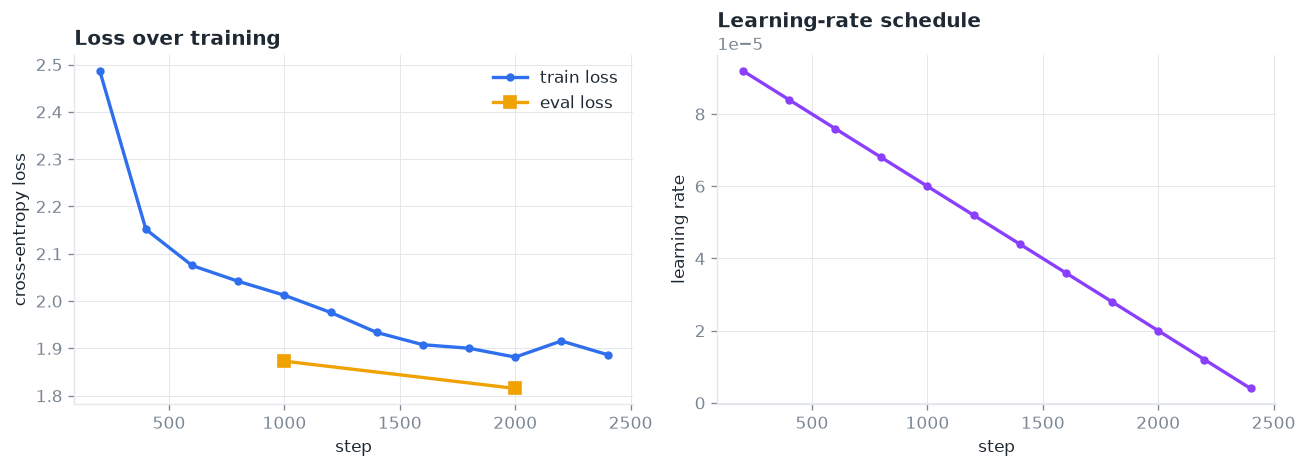

In [21]:
# Loss curves + learning-rate schedule.
!pip install -q matplotlib
import matplotlib.pyplot as plt

INK, MUTED, GRID = "#1f2933", "#7b8794", "#e4e7eb"
TRAIN, EVAL, LR = "#2f6fed", "#f0a202", "#8a3ffc"   # train / eval / lr
plt.rcParams.update({"figure.dpi": 120, "font.size": 10,
                     "axes.edgecolor": GRID, "axes.labelcolor": INK,
                     "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED})

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ts, tl = zip(*train)
ax[0].plot(ts, tl, color=TRAIN, lw=2, marker="o", ms=4, label="train loss")
if evals:
    es, el = zip(*evals)
    ax[0].plot(es, el, color=EVAL, lw=2, marker="s", ms=7, label="eval loss")
ax[0].set_title("Loss over training", loc="left", fontweight="bold")
ax[0].set_xlabel("step"); ax[0].set_ylabel("cross-entropy loss")
ax[0].grid(True, color=GRID, lw=0.6); ax[0].set_axisbelow(True)
ax[0].legend(frameon=False)

if lr:
    ls, lv = zip(*lr)
    ax[1].plot(ls, lv, color=LR, lw=2, marker="o", ms=4)
ax[1].set_title("Learning-rate schedule", loc="left", fontweight="bold")
ax[1].set_xlabel("step"); ax[1].set_ylabel("learning rate")
ax[1].grid(True, color=GRID, lw=0.6); ax[1].set_axisbelow(True)

for a in ax:
    a.spines["top"].set_visible(False); a.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig("training-metrics.png", bbox_inches="tight", facecolor="white")
plt.show()

In [22]:
# Headline numbers. Perplexity = exp(loss): the model's average "branching factor"
# when predicting the next token — lower is better, 1.0 is perfect.
final_train = train[-1][1]
best_eval   = min(v for _, v in evals) if evals else float("nan")
rows = [
    ("base model",       "t5-small (~60M params)"),
    ("train examples",   "20,000 (SQuAD subset)"),
    ("epochs",           2),
    ("final train loss", round(final_train, 4)),
    ("best eval loss",   round(best_eval, 4)),
    ("eval perplexity",  round(math.exp(best_eval), 2)),
]
try:
    import pandas as pd
    from IPython.display import display
    display(pd.DataFrame(rows, columns=["metric", "value"]))
except Exception:
    for k, v in rows:
        print(f"{k:18s} {v}")

,metric,value
0,base model,t5-small (~60M params)
1,train examples,"20,000 (SQuAD subset)"
2,epochs,2
3,final train loss,1.8868
4,best eval loss,1.8154
5,eval perplexity,6.14


### Generation quality on held-out SQuAD
QG has no single "accuracy" number — a good question can be phrased many ways, so
matching the human wording word-for-word is the wrong bar. These three metrics together
are the standard proxy: **ROUGE-L** and **BLEU** measure overlap with the human question,
and **exact match** is a strict lower bound. Expect modest overlap and near-zero exact
match — that's normal; skim the sample generations below to judge fluency for yourself.

In [23]:
# --- Generation quality on held-out SQuAD (a real 'accuracy' analog for QG) ---
# Generate questions for N validation examples, score them against the human-written
# reference questions with ROUGE-L, BLEU, and exact match. Reloads from disk so this
# works even after a kernel restart.
!pip install -q evaluate rouge_score sacrebleu
import torch, evaluate
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer
from datasets import load_dataset

MODEL_DIR, N, HL = "t5-small-qg", 200, "<hl>"
tok = AutoTokenizer.from_pretrained(MODEL_DIR)
mdl = AutoModelForSeq2SeqLM.from_pretrained(MODEL_DIR)
mdl = mdl.to("cuda" if torch.cuda.is_available() else "cpu").eval()

val = load_dataset("squad", split="validation").select(range(N))

def build_src(context, ans):
    a, s = ans["text"][0], ans["answer_start"][0]
    e = s + len(a)
    return f"generate question: {context[:s]} {HL} {a} {HL} {context[e:]}"

preds, refs = [], []
for i in range(0, len(val), 16):
    b = val[i:i + 16]
    srcs = [build_src(c, an) for c, an in zip(b["context"], b["answers"])]
    enc = tok(srcs, return_tensors="pt", padding=True, truncation=True, max_length=384).to(mdl.device)
    with torch.no_grad():
        out = mdl.generate(**enc, max_length=64, num_beams=4)
    preds += tok.batch_decode(out, skip_special_tokens=True)
    refs += b["question"]

rougeL = evaluate.load("rouge").compute(predictions=preds, references=refs)["rougeL"]
bleu = evaluate.load("sacrebleu").compute(predictions=preds, references=[[r] for r in refs])["score"]
em = sum(p.strip().lower() == r.strip().lower() for p, r in zip(preds, refs)) / len(preds)
print(f"On {N} held-out SQuAD examples:")
print(f"  ROUGE-L      {rougeL:.3f}   (question-word overlap vs. human question)")
print(f"  BLEU         {bleu:.1f}")
print(f"  Exact match  {em:.1%}   (identical to the human question)")
print("\nSample generations:")
for p, r in list(zip(preds, refs))[:6]:
    print(f"\n  model: {p}\n  human: {r}")


[notice] A new release of pip is available: 25.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


On 200 held-out SQuAD examples:
  ROUGE-L      0.388   (question-word overlap vs. human question)
  BLEU         14.3
  Exact match  0.5%   (identical to the human question)

Sample generations:

  model: Who defeated Carolina Panthers 24–10 to earn their third Super Bowl title?
  human: Which NFL team represented the AFC at Super Bowl 50?

  model: Who defeated the National Football Conference champion?
  human: Which NFL team represented the NFC at Super Bowl 50?

  model: Where was Levi's Stadium located?
  human: Where did Super Bowl 50 take place?

  model: Who defeated Carolina Panthers 24–10 to earn their third Super Bowl title?
  human: Which NFL team won Super Bowl 50?

  model: What was the name of the 50th Super Bowl?
  human: What color was used to emphasize the 50th anniversary of the Super Bowl?

  model: What was the theme of the 50th Super Bowl?
  human: What was the theme of Super Bowl 50?


## 7. Export to ONNX (for transformers.js)
`@xenova/transformers` runs ONNX models. This produces an `onnx/` folder with the encoder/decoder graphs plus the tokenizer + config — the exact layout transformers.js expects.

In [ ]:
# Export to ONNX for transformers.js, int8-quantized, laid out the way
# @xenova/transformers expects (onnx/ subfolder + tokenizer/config at the root).
# optimum 2.x ships the exporter as a separate package:
!pip install -q optimum-onnx onnx onnxruntime

import os, glob, shutil, onnx
from optimum.exporters.onnx import main_export
from onnxruntime.quantization import quantize_dynamic, QuantType

SRC, OUT = "t5-small-qg", "t5-small-qg-onnx"
ONNX = os.path.join(OUT, "onnx")

main_export(model_name_or_path=SRC, output=OUT,
            task="text2text-generation-with-past", opset=14)

os.makedirs(ONNX, exist_ok=True)
for f in glob.glob(os.path.join(OUT, "*.onnx")):
    shutil.move(f, os.path.join(ONNX, os.path.basename(f)))

# transformers.js (seq2seq + past) loads only encoder_model + decoder_model_merged.
KEEP = {"encoder_model.onnx", "decoder_model_merged.onnx"}
for f in glob.glob(os.path.join(ONNX, "*.onnx")):
    if os.path.basename(f) not in KEEP:
        os.remove(f)

for name in KEEP:
    src = os.path.join(ONNX, name)
    dst = os.path.join(ONNX, name.replace(".onnx", "_quantized.onnx"))
    # int8 dynamic quantization -> the *_quantized.onnx names transformers.js loads.
    # EnableSubgraph=True is REQUIRED: the merged decoder's weights live inside the
    # use-cache If-branches, and are otherwise skipped (decoder wouldn't shrink).
    quantize_dynamic(src, dst, weight_type=QuantType.QUInt8,
                     per_channel=False, reduce_range=False,
                     extra_options={"EnableSubgraph": True})
    os.remove(src)
    # onnxruntime-web (the WASM runtime in transformers.js 2.x) supports IR version
    # <= 8, but the exporter may stamp IR 9 -> "Unsupported model IR version: 9" in
    # the browser. Downgrade it (safe: opset 14 is valid under IR 8).
    m = onnx.load(dst)
    m.ir_version = 8
    onnx.save(m, dst)

for root, _, files in os.walk(OUT):
    for fn in sorted(files):
        p = os.path.join(root, fn)
        print(f"{os.path.relpath(p, OUT):45s} {os.path.getsize(p)/1e6:7.2f} MB")

# To self-host in the app: copy t5-small-qg-onnx/* into public/models/t5-small-qg/
# (default). Or push to the HF Hub and set VITE_QG_MODEL_ID + VITE_QG_MODEL_REMOTE.

## 8. Deploy
**Option A — Hugging Face Hub (easiest):**
```python
from huggingface_hub import notebook_login, upload_folder, create_repo
notebook_login()
create_repo("YOUR_USERNAME/t5-small-qg", exist_ok=True)
upload_folder(folder_path="t5-small-qg-onnx", repo_id="YOUR_USERNAME/t5-small-qg")
```
Then set `MODEL_ID = 'YOUR_USERNAME/t5-small-qg'` in `src/ml-ai/questionGen.js`.

**Option B — self-host:** zip `t5-small-qg-onnx/` and drop it under the app's `public/models/t5-small-qg/`, then set `MODEL_ID = '/models/t5-small-qg'` and `env.allowRemoteModels = false`.

See `notebooks/README.md` for wiring it into the app as a middle tier (Gemini → local ML → rule-based).

In [25]:
import sys, torch
print("kernel python:", sys.executable)
print("torch:", torch.__version__, "| cuda:", torch.cuda.is_available())

kernel python: c:\Users\ADMIN\AppData\Local\Programs\Python\Python312\python.exe
torch: 2.11.0+cu128 | cuda: True


In [26]:
import subprocess, sys
print(subprocess.run([sys.executable, "-m", "pip", "show", "torch"],
                     capture_output=True, text=True).stdout.split("Location")[0])

Name: torch
Version: 2.11.0+cu128
Summary: Tensors and Dynamic neural networks in Python with strong GPU acceleration
Home-page: https://pytorch.org
Author: 
Author-email: PyTorch Team <packages@pytorch.org>
License: BSD-3-Clause

